In [2]:
import zipfile
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
cwd = Path.cwd()
data_root = cwd.parent / 'data' if (cwd.parent / 'data').exists() else cwd / 'data'
zip_path = data_root / 'lowdim_algorithm_benchmark_data.zip'
DATA = data_root / 'lowdim_algorithm_benchmark_data'

if not DATA.exists():
    if not zip_path.exists():
        raise FileNotFoundError(
            f'Missing benchmark data. Expected either {DATA} or {zip_path}.'
        )
    DATA.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA)

required_files = [
    'lowdim_exact_oracle_benchmark_data.csv',
    'lowdim_exact_oracle_benchmark_local_search_data.csv',
]
missing = [name for name in required_files if not (DATA / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing benchmark data files in {DATA}: {", ".join(missing)}')

OUT = Path('outputs') / 'lowdim_algorithm_design_outputs'
FIG = OUT / 'figures'
OUT_DATA = OUT / 'data'
FIG.mkdir(parents=True, exist_ok=True)
OUT_DATA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA / 'lowdim_exact_oracle_benchmark_data.csv')
local_df = pd.read_csv(DATA / 'lowdim_exact_oracle_benchmark_local_search_data.csv')
if 'oracle_ratio' not in df.columns:
    if {'mse', 'oracle_mse'}.issubset(df.columns):
        df['oracle_ratio'] = df['mse'] / df['oracle_mse']
    else:
        df['oracle_ratio'] = df['risk'] / df['oracle_risk']

print(df.shape, local_df.shape)


(180, 13) (30, 14)


In [8]:
df.columns

Index(['cov_regime', 'signal_cost_regime', 'condition', 'rep', 'seed',
       'method', 'mse', 'lambda', 'support_size', 'support', 'oracle_mse',
       'gap_to_oracle', 'oracle_ratio'],
      dtype='str')

In [9]:
local_df.columns

Index(['cov_regime', 'signal_cost_regime', 'condition', 'rep', 'seed',
       'oracle_mse', 'greedy_raw_mse', 'greedy_refined_mse',
       'weighted_raw_mse', 'weighted_refined_mse', 'greedy_refinement_gain',
       'weighted_refinement_gain', 'greedy_refinement_gain_rel_oracle',
       'weighted_refinement_gain_rel_oracle'],
      dtype='str')

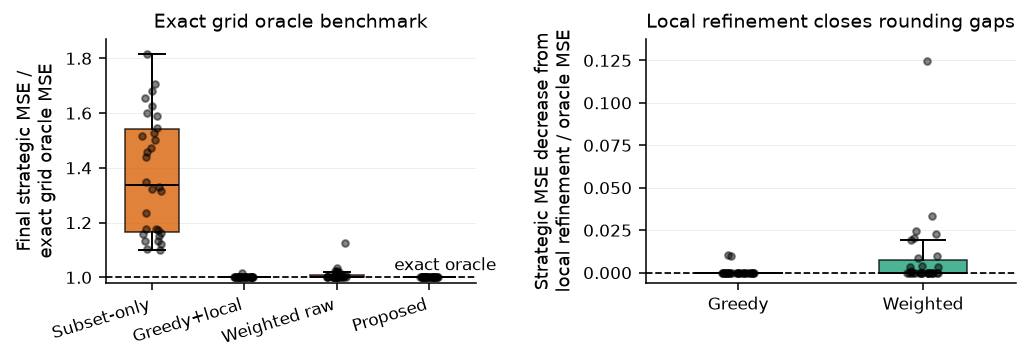

In [10]:
METHODS = [
    'Best subset (no reg.)',
    'Greedy + local refinement',
    'Weighted rounding only',
    'Weighted screen-and-refit (proposed)',
]
METHOD_LABELS = ['Subset-only', 'Greedy+local', 'Weighted raw', 'Proposed']
METHOD_COLORS = ['#D95F02', '#7570B3', '#E7298A', '#1B9E77']

plt.rcParams.update({
    'font.size': 8.5,
    'axes.titlesize': 9.6,
    'axes.labelsize': 9.0,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 8.5,
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

df['oracle_ratio'] = df['mse'] / df['oracle_mse']
oracle_lookup = df[df['method'].eq('Oracle subset-ridge (grid)')][['condition','rep','seed','oracle_mse']]

# Create a new variable to prevent multiple-run issues
local_df_merged = local_df.copy()
# Drop any existing oracle_mse columns from previous runs to be safe
local_df_merged = local_df_merged[[c for c in local_df_merged.columns if not c.startswith('oracle_mse')]]
local_df_merged = local_df_merged.merge(oracle_lookup, on=['condition','rep','seed'], how='left')
local_df_merged['greedy_gain_rel_oracle'] = local_df_merged['greedy_refinement_gain'] / local_df_merged['oracle_mse']
local_df_merged['weighted_gain_rel_oracle'] = local_df_merged['weighted_refinement_gain'] / local_df_merged['oracle_mse']

plot_df = df[df['method'].isin(METHODS)].copy()
groups = [plot_df.loc[plot_df['method'] == m, 'oracle_ratio'].values for m in METHODS]
rng = np.random.default_rng(123)

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.0))

ax = axes[0]
bp = ax.boxplot(groups, patch_artist=True, widths=0.58, showfliers=False)
for patch, color in zip(bp['boxes'], METHOD_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.78)
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(1.0)
for i, values in enumerate(groups, start=1):
    ax.scatter(i + rng.uniform(-0.11, 0.11, len(values)), values, color='black', s=12, alpha=0.48, zorder=3)
ax.set_xticks(range(1, len(METHOD_LABELS) + 1))
ax.set_xticklabels(METHOD_LABELS, rotation=17, ha='right')
ax.set_ylabel('Final strategic MSE /\nexact grid oracle MSE')
ax.set_title('Exact grid oracle benchmark', loc='center', pad=6)
ax.axhline(1.0, color='black', linestyle='--', linewidth=0.9)
ax.text(3.62, 1.012, 'exact oracle', fontsize=8.5, ha='left', va='bottom')
ax.set_ylim(0.98, max(plot_df['oracle_ratio'].max() * 1.03, 1.12))
ax.grid(axis='y', alpha=0.22, linewidth=0.5)

gain_df = pd.DataFrame({
    'pipeline': ['Greedy'] * len(local_df_merged) + ['Weighted'] * len(local_df_merged),
    'gain': np.concatenate([local_df_merged['greedy_gain_rel_oracle'].values, local_df_merged['weighted_gain_rel_oracle'].values]),
})
groups = [gain_df.loc[gain_df['pipeline'] == p, 'gain'].values for p in ['Greedy', 'Weighted']]
ax = axes[1]
bp = ax.boxplot(groups, patch_artist=True, widths=0.48, showfliers=False)
for patch, color in zip(bp['boxes'], ['#7570B3', '#1B9E77']):
    patch.set_facecolor(color)
    patch.set_alpha(0.78)
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(1.0)
for i, values in enumerate(groups, start=1):
    ax.scatter(i + rng.uniform(-0.09, 0.09, len(values)), values, color='black', s=12, alpha=0.48, zorder=3)
ax.set_xticks([1, 2])
ax.set_xticklabels(['Greedy', 'Weighted'])
ax.set_ylabel('Strategic MSE decrease from\nlocal refinement / oracle MSE')
ax.set_title('Local refinement closes rounding gaps', loc='center', pad=6)
ax.axhline(0.0, color='black', linestyle='--', linewidth=0.9)
ax.set_ylim(-0.006, max(0.135, gain_df['gain'].max() * 1.10))
ax.grid(axis='y', alpha=0.22, linewidth=0.5)

fig.subplots_adjust(left=0.13, right=0.985, bottom=0.28, top=0.86, wspace=0.46)
fig.savefig(FIG / 'lowdim_algorithm_design.pdf', bbox_inches='tight')
fig.savefig(FIG / 'lowdim_algorithm_design.png', bbox_inches='tight')
plt.show()
